# Exploratory Data Analysis: Road Conditions

### Source: SEMCOG road conditions map data

### Wayne County

In [1]:
#imports
import pandas as pd
import matplotlib.pyplot as plt

#load data
wayne_roads = pd.read_excel('data/tabular/wayne/wayne_county_roads.xlsx')
wayne_roads.head()

,OBJECTID,PR,BMP,EMP,LENMI,STRNAME,FALINK_ID,COUNTYL,COUNTYR,RU,...,AS_OF_18,AS_OF_19,AS_OF_20,AS_OF_21,AS_OF_22,AS_OF_23,AS_OF_24,LOC_ERROR,Shape_Leng,Shape__Length
0,25347,636410,0.00000,0.01170,0.01170,Inkster Rd,1050,163,163,4,...,5,5,5,6,6,6,8,NO ERROR,61.798961,61.798961
1,26293,644004,0.00951,0.01000,0.00049,Schaefer Hwy,1289,163,163,4,...,0,0,0,0,0,0,5,ZERO LENGTH EXTENT,0.000000,NaN
2,26576,646702,0.00000,0.00400,0.00400,Chrysler Dr S,1542,163,163,4,...,8,6,6,4,4,4,4,NO ERROR,22.751060,22.751060
3,27025,642401,0.05700,0.07668,0.01968,West End St,0,163,163,4,...,5,5,5,5,5,5,4,NO ERROR,103.936856,103.936856
4,27618,642508,0.00000,0.01200,0.01200,8 Mile Rd W,0,163,163,4,...,4,7,7,7,7,5,5,NO ERROR,63.854282,63.854282


In [52]:
wayne_roads['SEMMCDR']

0         1150
1            5
2            5
3            5
4            5
          ... 
168585       5
168586       5
168587       5
168588    1030
168589       5
Name: SEMMCDR, Length: 168590, dtype: int64

In [2]:
#how does the data work?
wayne_roads.columns

Index(['OBJECTID', 'PR', 'BMP', 'EMP', 'LENMI', 'STRNAME', 'FALINK_ID',
       'COUNTYL', 'COUNTYR', 'RU', 'RAMPID', 'LEGALSYSTE', 'NFC', 'NHS',
       'SEMROUNDID', 'FEDAID', 'FA', 'SEMMCDL', 'SEMMCDR', 'EVALYEAR',
       'SURFACE', 'LANES', 'LANEMI', 'VER', 'AS_OF_03', 'AS_OF_04', 'AS_OF_05',
       'AS_OF_06', 'AS_OF_07', 'AS_OF_08', 'AS_OF_09', 'AS_OF_10', 'AS_OF_11',
       'AS_OF_12', 'AS_OF_13', 'AS_OF_14', 'AS_OF_15', 'AS_OF_16', 'AS_OF_17',
       'AS_OF_18', 'AS_OF_19', 'AS_OF_20', 'AS_OF_21', 'AS_OF_22', 'AS_OF_23',
       'AS_OF_24', 'LOC_ERROR', 'Shape_Leng', 'Shape__Length'],
      dtype='str')

In [7]:
#Two main types of information
# - road info: length, street name, county, ramp #, lanes, surface type
# - PASER road condition rating: 2003 to 2024, when available

In [9]:
#What's the avg road condition? -> 5.3, or fair
wayne_roads['AS_OF_24'].mean()

np.float64(5.296002135357969)

In [10]:
#what about the median? -> about 5
wayne_roads['AS_OF_24'].median()

np.float64(5.0)

In [11]:
#how many of each rating? -> most roads are right in the middle in the fair category
wayne_roads['AS_OF_24'].value_counts()

AS_OF_24
5     31543
4     31523
6     27126
3     20813
7     19723
8     15884
2      8720
9      7560
10     3060
1      2638
Name: count, dtype: int64

(array([ 2638.,  8720., 20813., 31523., 31543., 27126., 19723., 15884.,
         7560.,  3060.]),
 array([ 1. ,  1.9,  2.8,  3.7,  4.6,  5.5,  6.4,  7.3,  8.2,  9.1, 10. ]),
 <BarContainer object of 10 artists>)

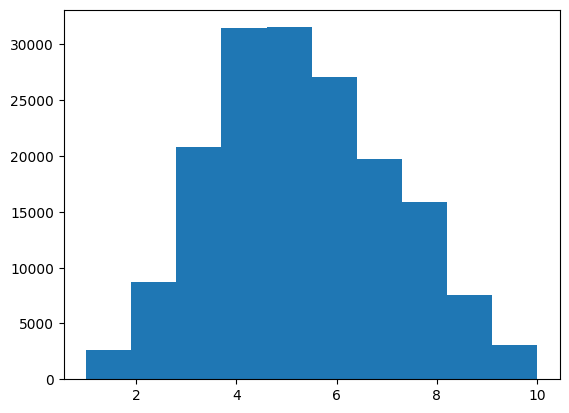

In [12]:
#distribution of road conditions
plt.hist(wayne_roads['AS_OF_24'])

In [18]:
#Where are the worst roads?
rating_by_street = wayne_roads[['STRNAME', 'AS_OF_24','OBJECTID']].groupby('STRNAME').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()

rating_by_street[rating_by_street['OBJECTID'] > 10].sort_values('AS_OF_24').head(10)

,STRNAME,OBJECTID,AS_OF_24
2615,Ecorse Service Drive A,11,1.090909
187,Allonby St,11,1.181818
3331,Gilbo St,43,1.279070
6297,Old Michigan Rd,16,1.437500
5381,Marygrove Dr,22,1.454545
1378,Castle St,21,1.714286
5571,Metroplex Dr,12,1.750000
3813,Hawthorne,14,1.785714
1986,Crossley St S,13,1.846154
2201,Denton Ave,20,1.850000


In [19]:
#The best roads?
rating_by_street[rating_by_street['OBJECTID'] > 10].sort_values('AS_OF_24', ascending=False).head(10)

,STRNAME,OBJECTID,AS_OF_24
1033,Brombach St,29,9.862069
8936,Weir St,18,9.611111
611,Beaconsfield Rd,29,9.517241
5105,Lyndon Rd,14,9.357143
1324,Carlton Rd,15,9.333333
5406,Maybury Grand St,59,9.322034
7934,Stamford Rd,20,9.100000
5171,Madison St,44,9.022727
1254,Campbell St S,12,9.000000
3778,Harvard,15,9.000000


In [34]:
#do roads that have gotten federal aid get better? -> Yes, federal aid seems to be worth 1 rating point higher on average
rating_by_fed_assist = wayne_roads[['FEDAID', 'AS_OF_24','OBJECTID']].groupby('FEDAID').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()

rating_by_fed_assist

,FEDAID,OBJECTID,AS_OF_24
0,No,100655,4.924713
1,Yes,67935,5.846118


In [40]:
#what about road types - is asphalt better than concrete, e.g.?

#types of roads 
wayne_roads['SURFACE'].value_counts()

SURFACE
Asphalt     113522
Concrete     53642
Gravel        1324
Brick          102
Name: count, dtype: int64

In [41]:
#avg rating by road surface -  gravel is best!
rating_by_surface = wayne_roads[['OBJECTID', 'SURFACE', 'AS_OF_24']].groupby('SURFACE').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()
rating_by_surface

,SURFACE,OBJECTID,AS_OF_24
0,Asphalt,113522,5.123386
1,Brick,102,4.039216
2,Concrete,53642,5.626561
3,Gravel,1324,6.800604


In [44]:
#avg rating by number of lanes - 6-lane is best, 2-lanes are worst
rating_by_lanes= wayne_roads[['OBJECTID', 'LANES', 'AS_OF_24']].groupby('LANES').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()
rating_by_lanes.sort_values('AS_OF_24', ascending=False)

,LANES,OBJECTID,AS_OF_24
5,6,361,6.249307
2,3,12490,6.055324
3,4,11950,5.677406
7,8,34,5.588235
4,5,9753,5.474726
6,7,896,5.466518
0,1,5834,5.340932
1,2,127272,5.165936


In [59]:
#rating by the length of the segment -> 2-rated roads are the longest, 10-rated roads are the shortest, but there's no clear length = rating situation
wayne_roads[['OBJECTID', 'Shape_Leng', 'AS_OF_24']].groupby('AS_OF_24').agg({
    'OBJECTID': 'count',
    'Shape_Leng': 'mean'
}).reset_index().sort_values('Shape_Leng', ascending=False)

,AS_OF_24,OBJECTID,Shape_Leng
1,2,8720,251.576336
7,8,15884,240.943256
0,1,2638,240.897765
4,5,31543,240.148311
5,6,27126,235.438904
8,9,7560,235.150541
6,7,19723,226.460703
3,4,31523,225.307423
2,3,20813,224.294498
9,10,3060,158.023712


In [45]:
#regression using lanes, surface and fed aid - how much do they each contribute?
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# simple regression: predict AS_OF_24 from SURFACE, FEDAID, LANES

# prepare data
cols = ['AS_OF_24', 'SURFACE', 'FEDAID', 'LANES']
df = wayne_roads[cols].copy()

# clean & convert
df['LANES'] = pd.to_numeric(df['LANES'], errors='coerce')
df = df.dropna(subset=['AS_OF_24', 'SURFACE', 'FEDAID', 'LANES'])

# one-hot encode categorical predictors
X = pd.get_dummies(df[['SURFACE', 'FEDAID', 'LANES']], drop_first=True)
y = df['AS_OF_24']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# fit model
model = LinearRegression()
model.fit(X_train, y_train)

# predict & evaluate
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Intercept:", model.intercept_)
coef_df = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df)

print("\nTrain R2:", r2_score(y_train, y_train_pred))
print("Test R2 :", r2_score(y_test, y_test_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Test MSE:", mean_squared_error(y_test, y_test_pred))

Intercept: 4.831712774422209
            feature  coefficient
3    SURFACE_Gravel     1.967503
4        FEDAID_Yes     1.044195
1     SURFACE_Brick    -0.921077
2  SURFACE_Concrete     0.577805
0             LANES    -0.065317

Train R2: 0.0779307488912091
Test R2 : 0.0736431181425754
Test MAE: 1.563622819468064
Test MSE: 3.68908122340391


**These three variables (federal aid, number of lanes and surface type) don't seem to explain road conditions that strongly, low r-squared value. My hunch is that it has much more to do with traffic volume.**

In [46]:
#more comprehensive regression
wayne_roads.describe()

,OBJECTID,PR,BMP,EMP,LENMI,FALINK_ID,COUNTYL,COUNTYR,RU,LEGALSYSTE,...,AS_OF_17,AS_OF_18,AS_OF_19,AS_OF_20,AS_OF_21,AS_OF_22,AS_OF_23,AS_OF_24,Shape_Leng,Shape__Length
count,168590.000000,1.685900e+05,168590.000000,168590.000000,1.685900e+05,168590.000000,168590.000000,168590.000000,168590.000000,168590.000000,...,168590.000000,168590.000000,168590.000000,168590.000000,168590.000000,168590.000000,168590.000000,168590.000000,168590.000000,91105.000000
mean,260743.117089,2.370865e+06,1.991466,2.035339,4.387329e-02,6179.613186,162.905119,162.942013,3.991619,3.767637,...,1.847120,2.087538,2.140685,2.147185,2.331236,2.350792,2.400979,5.296002,232.020125,429.353744
std,72435.618283,1.336740e+06,3.922011,3.919426,6.586310e-02,7966.275764,2.029521,1.662666,0.158347,1.419654,...,2.747371,2.759502,2.762161,2.759755,2.882801,2.897394,2.935361,1.989249,348.430321,374.074944
min,25347.000000,6.364100e+05,0.000000,0.001000,2.607700e-11,0.000000,99.000000,115.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.295285
25%,203042.250000,1.604908e+06,0.143000,0.187438,3.000000e-05,0.000000,163.000000,163.000000,4.000000,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000,195.728066
50%,245192.500000,1.642406e+06,0.469000,0.502000,9.640000e-03,0.000000,163.000000,163.000000,4.000000,4.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,51.868452,324.485396
75%,289963.250000,1.804001e+06,1.627245,1.669000,6.261000e-02,14179.000000,163.000000,163.000000,4.000000,5.000000,...,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000,7.000000,331.433193,618.653437
max,401268.000000,6.802252e+06,38.291000,38.457790,1.459000e+00,22699.000000,163.000000,163.000000,4.000000,9.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,7706.640845,7706.640845


In [55]:
#Now, using all of the numeric rows 

# prepare data
cols = ['AS_OF_24', 'SURFACE', 'FEDAID', 'LANES', 'PR', 'BMP', 'EMP', 'LENMI', 'COUNTYL', 'COUNTYR', 'RU', 'LEGALSYSTE',  'NFC', 'NHS', 'SEMMCDL', 'SEMMCDR', 'LANEMI']
df = wayne_roads[cols].copy()

# clean & convert
df['LANES'] = pd.to_numeric(df['LANES'], errors='coerce')
df = df.dropna()

# one-hot encode categorical predictors
X = pd.get_dummies(df[['SURFACE', 'FEDAID', 'LANES', 'PR', 'BMP', 'EMP', 'LENMI', 'COUNTYL', 'COUNTYR', 'RU', 'LEGALSYSTE',  'NFC', 'NHS', 'SEMMCDL', 'SEMMCDR', 'LANEMI']], drop_first=True)
y = df['AS_OF_24']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# fit model
model = LinearRegression()
model.fit(X_train, y_train)

# predict & evaluate
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Intercept:", model.intercept_)
coef_df = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df)

print("\nTrain R2:", r2_score(y_train, y_train_pred))
print("Test R2 :", r2_score(y_test, y_test_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Test MSE:", mean_squared_error(y_test, y_test_pred))

Intercept: 3.909652067040387
             feature   coefficient
16    SURFACE_Gravel  2.018817e+00
14     SURFACE_Brick -8.783123e-01
17        FEDAID_Yes  7.972955e-01
15  SURFACE_Concrete  5.683900e-01
4              LENMI -4.395393e-01
7                 RU -2.561937e-01
2                BMP  2.274323e-01
3                EMP -2.121069e-01
10               NHS -2.030046e-01
9                NFC -1.533341e-01
8         LEGALSYSTE  1.320910e-01
13            LANEMI  1.261521e-01
0              LANES -6.527565e-02
5            COUNTYL  1.031702e-02
6            COUNTYR  4.494813e-03
11           SEMMCDL  1.667887e-04
12           SEMMCDR -5.538886e-05
1                 PR -2.270794e-08

Train R2: 0.08292149503843071
Test R2 : 0.07852736481416844
Test MAE: 1.5580039813276951
Test MSE: 3.669630423135099


### Oakland County

In [60]:
#load data
oakland_roads = pd.read_excel('data/tabular/oakland/oakland_county_roads.xlsx')
oakland_roads.head()

c:\Users\BWarren\PythonProjects\motor_city_driving\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,OBJECTID,PR,BMP,EMP,LENMI,STRNAME,FALINK_ID,COUNTYL,COUNTYR,RU,...,AS_OF_18,AS_OF_19,AS_OF_20,AS_OF_21,AS_OF_22,AS_OF_23,AS_OF_24,LOC_ERROR,Shape_Leng,Shape__Length
0,1,609508,0.13012,0.20711,0.07699,Stoney Creek Rd,143,125,125,4,...,2,3,3,2,2,3,3,NO ERROR,405.808971,405.808971
1,2,604708,2.04500,2.14753,0.10253,Orion Rd,11,125,125,4,...,6,6,6,7,7,8,8,NO ERROR,549.265219,549.265219
2,3,604002,0.91907,1.17692,0.25785,Army Rd,0,125,125,1,...,0,0,0,0,0,5,5,NO ERROR,1361.695188,1361.695188
3,4,606408,0.30800,0.45577,0.14777,Frankson Ave,0,125,125,4,...,5,5,5,5,5,5,5,NO ERROR,781.711432,781.711432
4,5,606104,0.00000,0.06286,0.06286,Cal Ave,0,125,125,4,...,5,5,5,4,4,4,4,NO ERROR,332.007876,332.007876


In [61]:
#summary stats for rating column -> very similar to Wayne County
oakland_roads['AS_OF_24'].describe()

count    112031.000000
mean          5.186770
std           2.164345
min           1.000000
25%           4.000000
50%           5.000000
75%           7.000000
max          10.000000
Name: AS_OF_24, dtype: float64

(array([ 3216.,  9496., 13915., 19550., 18016., 15167., 13803., 10802.,
         5853.,  2213.]),
 array([ 1. ,  1.9,  2.8,  3.7,  4.6,  5.5,  6.4,  7.3,  8.2,  9.1, 10. ]),
 <BarContainer object of 10 artists>)

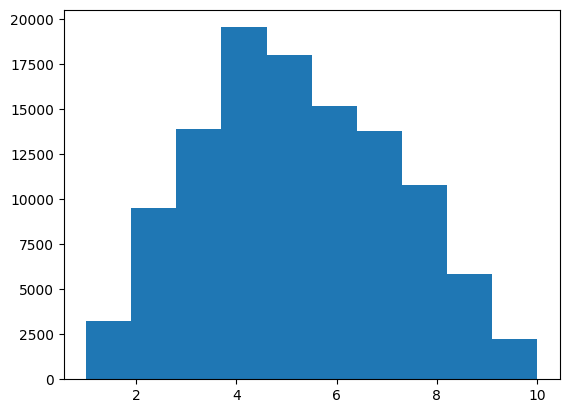

In [62]:
plt.hist(oakland_roads['AS_OF_24'])

In [63]:
#Where are the worst roads?
rating_by_street_oak = oakland_roads[['STRNAME', 'AS_OF_24','OBJECTID']].groupby('STRNAME').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()

rating_by_street_oak[rating_by_street_oak['OBJECTID'] > 10].sort_values('AS_OF_24').head(10)

,STRNAME,OBJECTID,AS_OF_24
7051,Lake Knolls Dr,13,1.000000
3571,Dogwood Trl,13,1.000000
7899,Manitou Rd,13,1.076923
5551,Harvey Ave,14,1.142857
9309,Old Milford Farms,12,1.166667
6907,Kirkway Rd,12,1.166667
13976,Winding Dr S,11,1.181818
8652,Motorway Dr,11,1.181818
2389,Cherry Grove Ln,19,1.263158
9446,Oregon Blvd,13,1.307692


In [64]:
#Where are the best roads?
rating_by_street_oak[rating_by_street_oak['OBJECTID'] > 10].sort_values('AS_OF_24', ascending=False).head(10)

,STRNAME,OBJECTID,AS_OF_24
3666,Drahner Rd W,45,9.555556
8170,Maybee Rd,80,9.287500
11502,Seymour Lake Rd,32,9.218750
7637,Loon Lake Rd,77,9.155844
3804,E I 96,265,9.143396
684,Avon Rd E,38,9.105263
12014,Squirrel Ct,18,9.055556
2387,Cherry Dr,18,9.000000
7197,Lapeer Rd N,13,9.000000
13099,Vanden Dr,15,9.000000


In [66]:
#avg rating by road surface -  concrete is better
rating_by_surface_oak = oakland_roads[['OBJECTID', 'SURFACE', 'AS_OF_24']].groupby('SURFACE').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()
rating_by_surface_oak

,SURFACE,OBJECTID,AS_OF_24
0,Asphalt,74466,5.079540
1,Brick,7,7.428571
2,Concrete,29697,5.447453
3,Gravel,7861,5.215749


In [67]:
#avg rating by number of lanes
rating_by_lanes_oak = oakland_roads[['OBJECTID', 'LANES', 'AS_OF_24']].groupby('LANES').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()
rating_by_lanes_oak.sort_values('AS_OF_24', ascending=False)

,LANES,OBJECTID,AS_OF_24
2,3,9466,6.254701
3,4,5304,6.058258
5,6,342,5.842105
4,5,5694,5.758869
0,1,3202,5.688632
6,7,127,5.370079
1,2,87879,4.961322
7,8,17,3.352941


### Macomb County

In [68]:
# Load Macomb County data
macomb_roads = pd.read_excel('data/tabular/macomb/macomb_county_roads.xlsx')
macomb_roads.head()

c:\Users\BWarren\PythonProjects\motor_city_driving\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,OBJECTID,PR,BMP,EMP,LENMI,STRNAME,FALINK_ID,COUNTYL,COUNTYR,RU,...,AS_OF_18,AS_OF_19,AS_OF_20,AS_OF_21,AS_OF_22,AS_OF_23,AS_OF_24,LOC_ERROR,Shape_Leng,Shape__Length
0,46445,667605,6.31807,6.64300,0.32493,Dequindre Rd,2436,125,99,1,...,4,5,5,7,7,5,5,NO ERROR,1716.622789,1716.622789
1,46527,667605,5.64745,6.05500,0.40755,Dequindre Rd,2436,125,99,1,...,4,5,5,8,8,8,8,NO ERROR,2153.306862,2153.306862
2,46668,667605,3.73600,4.13800,0.40200,Dequindre Rd,2435,125,99,1,...,4,6,6,8,8,8,8,NO ERROR,2125.405778,2125.405778
3,46714,667605,1.52775,1.54174,0.01399,Dequindre Rd,2434,99,99,4,...,4,5,5,5,5,5,5,NO ERROR,75.181396,75.181396
4,47307,667605,1.54200,1.70369,0.16169,Dequindre Rd,2434,99,99,4,...,4,5,5,5,5,6,6,NO ERROR,857.017910,857.017910


In [69]:
macomb_roads['AS_OF_24'].describe()

count    58465.000000
mean         5.438639
std          2.123513
min          1.000000
25%          4.000000
50%          5.000000
75%          7.000000
max         10.000000
Name: AS_OF_24, dtype: float64

In [71]:
#Where are the worst roads?
rating_by_street_mac = macomb_roads[['STRNAME', 'AS_OF_24','OBJECTID']].groupby('STRNAME').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()

rating_by_street_mac[rating_by_street_mac['OBJECTID'] > 10].sort_values('AS_OF_24', ascending=False).head(10)

,STRNAME,OBJECTID,AS_OF_24
428,Bailey St N,19,10.000000
2872,Greenbriar Ave,21,9.000000
4131,Lyons Cir E,12,9.000000
1588,Cosgrove Dr,11,9.000000
3364,Inwood Rd,14,9.000000
7000,Waltham Rd,41,9.000000
5279,Plumbrook Rd,94,8.808511
1272,Chartier St,12,8.750000
1375,Civic Center Dr N,22,8.727273
4040,Long St,12,8.666667


In [ ]:
rating_by_street_mac = macomb_roads[['STRNAME', 'AS_OF_24','OBJECTID']].groupby('STRNAME').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()

rating_by_street_mac[rating_by_street_mac['OBJECTID'] > 10].sort_values('AS_OF_24', ascending=False).head(10)

In [72]:
#avg rating by road surface
rating_by_surface_mac = macomb_roads[['OBJECTID', 'SURFACE', 'AS_OF_24']].groupby('SURFACE').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()
rating_by_surface_mac

,SURFACE,OBJECTID,AS_OF_24
0,Asphalt,22154,5.579128
1,Brick,9,5.111111
2,Concrete,35126,5.292746
3,Gravel,1176,7.152211


In [73]:
#avg rating by number of lanes
rating_by_lanes_mac = macomb_roads[['OBJECTID', 'LANES', 'AS_OF_24']].groupby('LANES').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()
rating_by_lanes_mac.sort_values('AS_OF_24', ascending=False)

,LANES,OBJECTID,AS_OF_24
2,3,5828,6.929307
3,4,3960,6.780556
0,1,1114,6.548474
5,6,30,6.500000
4,5,5458,6.082081
6,7,414,5.654589
1,2,41661,4.985670


### Combining all three counties

In [75]:
metro_roads = pd.concat([wayne_roads, macomb_roads, oakland_roads])
metro_roads.head()

,OBJECTID,PR,BMP,EMP,LENMI,STRNAME,FALINK_ID,COUNTYL,COUNTYR,RU,...,AS_OF_18,AS_OF_19,AS_OF_20,AS_OF_21,AS_OF_22,AS_OF_23,AS_OF_24,LOC_ERROR,Shape_Leng,Shape__Length
0,25347,636410,0.00000,0.01170,0.01170,Inkster Rd,1050,163,163,4,...,5,5,5,6,6,6,8,NO ERROR,61.798961,61.798961
1,26293,644004,0.00951,0.01000,0.00049,Schaefer Hwy,1289,163,163,4,...,0,0,0,0,0,0,5,ZERO LENGTH EXTENT,0.000000,NaN
2,26576,646702,0.00000,0.00400,0.00400,Chrysler Dr S,1542,163,163,4,...,8,6,6,4,4,4,4,NO ERROR,22.751060,22.751060
3,27025,642401,0.05700,0.07668,0.01968,West End St,0,163,163,4,...,5,5,5,5,5,5,4,NO ERROR,103.936856,103.936856
4,27618,642508,0.00000,0.01200,0.01200,8 Mile Rd W,0,163,163,4,...,4,7,7,7,7,5,5,NO ERROR,63.854282,63.854282


In [76]:
len(metro_roads)

339086

In [77]:
#average road rating
metro_roads['AS_OF_24'].mean()

np.float64(5.284505995529158)

In [78]:
#best roads in metro Detroit
rating_by_street_metro = metro_roads[['STRNAME', 'AS_OF_24','OBJECTID']].groupby('STRNAME').agg({
    'OBJECTID': 'count',
    'AS_OF_24': 'mean'
}).reset_index()

rating_by_street_metro[rating_by_street_metro['OBJECTID'] > 10].sort_values('AS_OF_24', ascending=False).head(10)

,STRNAME,OBJECTID,AS_OF_24
1392,Bailey St N,19,10.000000
3056,Brombach St,29,9.862069
25562,Weir St,18,9.611111
6835,Drahner Rd W,45,9.555556
1757,Beaconsfield Rd,29,9.517241
14562,Lyndon Rd,14,9.357143
3825,Carlton Rd,15,9.333333
15416,Maybury Grand St,59,9.322034
15410,Maybee Rd,80,9.287500
21734,Seymour Lake Rd,32,9.218750


In [ ]:
#worst roads in metro Detroit
rating_by_street_metro[rating_by_street_metro['OBJECTID'] > 10].sort_values('AS_OF_24').head(10)

,STRNAME,OBJECTID,AS_OF_24
13286,Lake Knolls Dr,13,1.000000
6639,Dogwood Trl,13,1.000000
14908,Manitou Rd,13,1.076923
7416,Ecorse Service Drive A,11,1.090909
12989,Kirkway Rd,12,1.166667
17682,Old Milford Farms,12,1.166667
16402,Motorway Dr,11,1.181818
26296,Winding Dr S,11,1.181818
521,Allonby St,11,1.181818
5245,Conners Ave,19,1.263158
